In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from cognitive_maps_in_llms.analysis import (
    get_fwd_fwd_context_tokens,
    RunResults,
    plot_erasure_trajectory,
    plot_remaining_key_values,
)

In [2]:
REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'cognitive_maps_in_llms').is_dir()
)

# SET INPUT AND OUTPUT PATHS

# ------------------------------------------------------------------------------
RESULTS_ROOT = REPO_ROOT / 'results/final_run_2026-09-30'
FIGURES_DIR  = REPO_ROOT / 'figures/generated/supplementary/figure_s5'
SAVE_FIGURES = True
# ------------------------------------------------------------------------------

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RESULTS = RunResults(results_root=RESULTS_ROOT)

In [3]:
# LOAD AN ERASURE TRAJECTORY

MODEL_PRESET  = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_who_is'

TRAJECTORY = RESULTS.load_erasure_trajectory(
    model_preset=MODEL_PRESET, 
    prompt_preset=PROMPT_PRESET
)

In [4]:
# RETRIEVE INFO ABOUT "KEY POINTS" IN THE TRAJECTORY

CONDITION_NAMES = (
    "FIDELITY_50",
    "FIDELITY_80",
    "FIDELITY_95",
    "FIDELITY_95_SITES_X2",
)

from cognitive_maps_in_llms.experiments.utils_erasure import load_erasure_conditions
conditions = load_erasure_conditions(TRAJECTORY.directory, CONDITION_NAMES)

def phase_at_iteration(iteration):
    next_round = iteration + 1
    n_erased = (
        (TRAJECTORY.key_erasure_round_tli == next_round).sum()
        + (TRAJECTORY.value_erasure_round_tli == next_round).sum()
    )
    return "fine" if n_erased == 1 else "coarse"

FINE_START_ITERATION = next(
    iteration
    for iteration in range(len(TRAJECTORY.score_by_iteration))
    if phase_at_iteration(iteration) == "fine"
)

for condition_name in CONDITION_NAMES:
    condition = conditions[condition_name]
    iteration = condition.iteration

    score = TRAJECTORY.score_by_iteration[iteration]
    fidelity = (
        (score - TRAJECTORY.fully_erased_score)
        / (TRAJECTORY.initial_score - TRAJECTORY.fully_erased_score)
    )
    phase = phase_at_iteration(iteration)

    print(f'"{condition_name}":')
    print(f'Iteration: {iteration} (during "{phase}" phase)')
    print(f"Score: {score:g}")
    print(f"Fidelity: {fidelity:.3f}")
    print(f"Remaining keys: {condition.n_keys}")
    print(f"Remaining values: {condition.n_values}")
    print()

"FIDELITY_50":
Iteration: 186 (during "fine" phase)
Score: 15.4417
Fidelity: 0.511
Remaining keys: 39
Remaining values: 8

"FIDELITY_80":
Iteration: 155 (during "fine" phase)
Score: 29.1708
Fidelity: 0.802
Remaining keys: 54
Remaining values: 24

"FIDELITY_95":
Iteration: 112 (during "fine" phase)
Score: 36.25
Fidelity: 0.952
Remaining keys: 69
Remaining values: 52

"FIDELITY_95_SITES_X2":
Iteration: 35 (during "coarse" phase)
Score: 37.8333
Fidelity: 0.985
Remaining keys: 112
Remaining values: 131



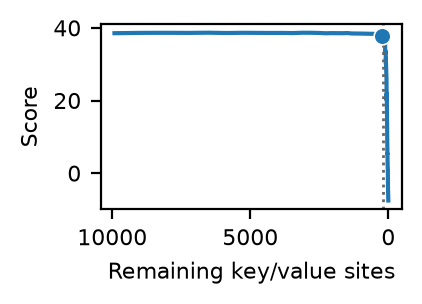

In [5]:
# PLOT AN ERASURE TRAJECTORY...

plot = plot_erasure_trajectory(
    TRAJECTORY,
    x_axis='remaining_sites',
    transition_iteration=FINE_START_ITERATION,
    marked_iterations={
        "FIDELITY_95_SITES_X2": conditions["FIDELITY_95_SITES_X2"].iteration,
    },
)

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'erasure_trajectory_zoomed_out.svg')
plt.close(plot.fig)

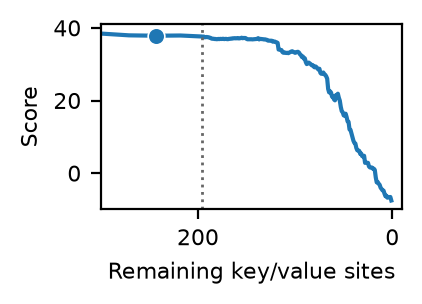

In [6]:
# ...AND A ZOOMED IN VERSION

plot.ax.set_xlim((300, -10))

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'erasure_trajectory_zoomed_in.svg')
plt.close(plot.fig)

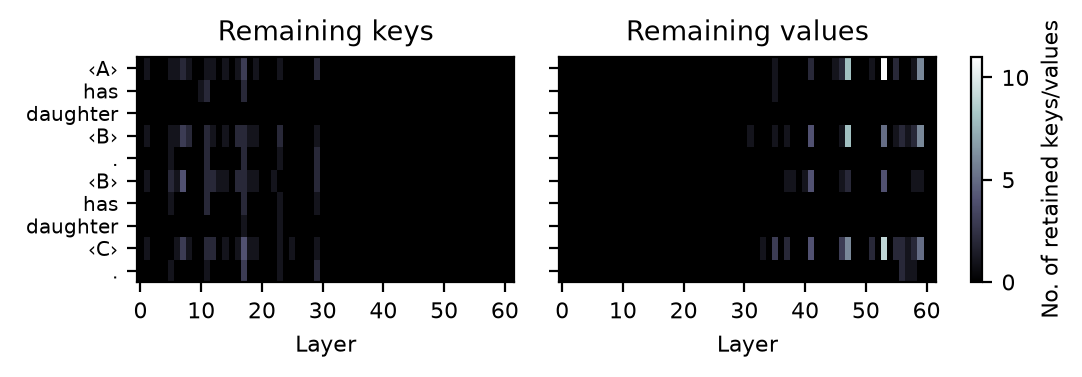

In [7]:
# PLOT REMAINING KEYS AND VALUES

plot = plot_remaining_key_values(
    TRAJECTORY,
    iteration=conditions["FIDELITY_95_SITES_X2"].iteration,
    token_labels=get_fwd_fwd_context_tokens(MODEL_PRESET, PROMPT_PRESET),
)
# Note that context-token labels require local tokenizer files under LNT_MODELS_DIR for the selected model preset

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'key_value_distribution.svg')
plt.close(plot.fig)